In [12]:
from pathlib import Path
from datasets import load_from_disk

import pandas as pd
import numpy as np
import torch

from transformers import set_seed

SEED = 42

set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [7]:
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
reports_dir = project_dir / "reports"

tokenized_dataset = load_from_disk(
    str(data_dir / "healthbrief_tokenized")
)

prepared_dataset = load_from_disk(
    str(data_dir / "healthbrief_prepared")
)

manifest_df = pd.read_csv(
    reports_dir / "dataset_split_manifest.csv"
)

print("Project directory:", project_dir)

print("\nTokenized Dataset:")
display(tokenized_dataset)

print("\nPrepared Dataset:")
display(prepared_dataset)

print("\nDataset Split Manifest:")
display(manifest_df.groupby("split").size())


assert len(tokenized_dataset["train"]) == 500
assert len(tokenized_dataset["validation"]) == 100

assert len(prepared_dataset["train"]) == 500
assert len(prepared_dataset["validation"]) == 100

assert (manifest_df["split"] == "final_holdout").sum() == 100

print("Dataset sample counts: PASS")


Project directory: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief

Tokenized Dataset:


DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 500
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 100
    })
})


Prepared Dataset:


DatasetDict({
    train: Dataset({
        features: ['split', 'article_id', 'input_text', 'target_summary', 'source_token_count', 'target_token_count', 'source_sections'],
        num_rows: 500
    })
    validation: Dataset({
        features: ['split', 'article_id', 'input_text', 'target_summary', 'source_token_count', 'target_token_count', 'source_sections'],
        num_rows: 100
    })
})


Dataset Split Manifest:


split
final_holdout    100
original_test    100
train            500
validation       100
dtype: int64

Dataset sample counts: PASS


In [9]:
train_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "train", "article_id"
    ]
)

validation_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "validation", "article_id"
    ]
)

final_holdout_ids = set(
    manifest_df.loc[
        manifest_df["split"] == "final_holdout", "article_id"
    ]
)

train_validation_overlap = train_ids.intersection(validation_ids)

train_holdout_overlap = train_ids.intersection(final_holdout_ids)

validation_holdout_overlap = validation_ids.intersection(final_holdout_ids)

print("Train-validation overlap:", len(train_validation_overlap))

print("Train-holdout overlap:", len(train_holdout_overlap))

print("Validation-holdout overlap:", len(validation_holdout_overlap))

Train-validation overlap: 0
Train-holdout overlap: 0
Validation-holdout overlap: 0


In [10]:
prepared_train_ids = set(
    prepared_dataset["train"]["article_id"]
)

prepared_validation_ids = set(
    prepared_dataset["validation"]["article_id"]
)

assert len(train_ids) == 500
assert len(validation_ids) == 100
assert len(final_holdout_ids) == 100

assert not train_validation_overlap
assert not train_holdout_overlap
assert not validation_holdout_overlap

assert prepared_train_ids == train_ids
assert prepared_validation_ids == validation_ids

print("Dataset manifest consistency: PASS")
print("Data leakage validation: PASS")

Dataset manifest consistency: PASS
Data leakage validation: PASS


In [11]:
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 768

length_records = []

for split in ["train", "validation"]:

    source_lengths = [
        len(x) for x in tokenized_dataset[split]["input_ids"]
    ]

    target_lengths = [
        len(x) for x in tokenized_dataset[split]["labels"]
    ]

    length_records.append({
        "split": split,
        "sample_count": len(tokenized_dataset[split]),
        "source_min": min(source_lengths),
        "source_max": max(source_lengths),
        "source_mean": np.mean(source_lengths),
        "target_min": min(target_lengths),
        "target_max": max(target_lengths),
        "target_mean": np.mean(target_lengths)
    })

length_df = pd.DataFrame(length_records)

display(length_df)

,split,sample_count,source_min,source_max,source_mean,target_min,target_max,target_mean
0,train,500,511,512,511.898,258,768,521.33
1,validation,100,511,512,511.890,302,759,521.41


In [14]:
import platform
import transformers
import peft
import datasets

environment_info = {
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
    "datasets_version": datasets.__version__,
    "cuda_version": torch.version.cuda,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": SEED
}

environment_df = pd.DataFrame(
    environment_info.items(),
    columns=["feature", "value"]
)

display(environment_df)


,feature,value
0,python_version,3.14.4
1,pytorch_version,2.14.1+cu130
2,transformers_version,5.14.1
3,peft_version,0.22.0
4,datasets_version,5.1.0
5,cuda_version,13.0
6,cuda_available,True
7,gpu_name,NVIDIA GeForce RTX 4060 Laptop GPU
8,seed,42


In [16]:
import json

with open(data_dir / "dataset_metadata.json", "r") as file:
    dataset_metadata = json.load(file)

display(dataset_metadata)

from huggingface_hub import HfApi

MODEL_NAME = "google/flan-t5-small"

api = HfApi()

model_info = api.model_info(MODEL_NAME)

model_revision = model_info.sha

tokenizer_revision = model_revision

print("Model name:", MODEL_NAME)
print("Model revision:", model_revision)
print("Tokenizer revision:", tokenizer_revision)

{'dataset': 'BioLaySumm/BioLaySumm2025-eLife',
 'revision': '144e9c785e3a309da804eb6786feb38e6596f390',
 'seed': 42,
 'sampling_method': 'streaming_buffer_shuffle',
 'buffer_size': 1000,
 'sample_sizes': {'train': 500, 'validation': 100, 'test': 100},
 'license': None,
 'test_references_available': False}

Model name: google/flan-t5-small
Model revision: 0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab
Tokenizer revision: 0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab


In [18]:
environment_info.update({
    "dataset_name": dataset_metadata["dataset"] , 
    "dataset_revision": dataset_metadata["revision"] , 
    "model_name": MODEL_NAME,
    "model_revision": model_revision,
    "tokenizer_revision": tokenizer_revision
})

environment_df = pd.DataFrame(
    environment_info.items(),
    columns=["feature", "value"]
)

display(environment_df)

environment_df.to_csv(
    reports_dir / "training_environment.csv",
    index=False
)

print("Training environment saved successfully.")

,feature,value
0,python_version,3.14.4
1,pytorch_version,2.14.1+cu130
2,transformers_version,5.14.1
3,peft_version,0.22.0
4,datasets_version,5.1.0
5,cuda_version,13.0
6,cuda_available,True
7,gpu_name,NVIDIA GeForce RTX 4060 Laptop GPU
8,seed,42
9,dataset_name,BioLaySumm/BioLaySumm2025-eLife


Training environment saved successfully.


In [19]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

set_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    revision= tokenizer_revision
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    revision=model_revision
)

base_total_parameters = sum(
    p.numel() for p in model.parameters()
)

base_trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model architecture:", type(model).__name__)
print("Total parameters:", base_total_parameters)
print("Trainable parameters:", base_trainable_parameters)
print("Model dtype:", next(model.parameters()).dtype)
print("Model device:", next(model.parameters()).device)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 2260.66it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model architecture: T5ForConditionalGeneration
Total parameters: 76961152
Trainable parameters: 76961152
Model dtype: torch.float32
Model device: cpu


In [21]:
def tokenize_function(examples):

    model_inputs = tokenizer(
        examples["input_text"],
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        padding=False
    )

    target_tokens = tokenizer(
        text_target=examples["target_summary"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
        padding=False
    )

    model_inputs["labels"] = target_tokens["input_ids"]

    return model_inputs



new_sample = tokenize_function(
    prepared_dataset["train"][0]
)

saved_sample = tokenized_dataset["train"][0]

assert new_sample["input_ids"] == saved_sample["input_ids"]

assert new_sample["attention_mask"] == saved_sample["attention_mask"]

assert new_sample["labels"] == saved_sample["labels"]

print("Tokenizer consistency: PASS")

Tokenizer consistency: PASS


In [22]:
verification_dataset = prepared_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=prepared_dataset["train"].column_names
)

for split in ["train", "validation"]:

    assert len(verification_dataset[split]) == len(tokenized_dataset[split])

    for column in ["input_ids", "attention_mask", "labels"]:

        assert list(verification_dataset[split][column]) == tokenized_dataset[split][column]

    print(f"{split} tokenizer consistency: PASS")

print("Full dataset tokenizer consistency: PASS")

Map: 100%|██████████| 100/100 [00:00<00:00, 1220.26 examples/s]


train tokenizer consistency: PASS
validation tokenizer consistency: PASS
Full dataset tokenizer consistency: PASS


In [23]:
set_seed(SEED)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q", "v"],
    bias="none",
    inference_mode=False
)

lora_model = get_peft_model(model, lora_config)

lora_model.print_trainable_parameters()

trainable params: 344,064 || all params: 77,305,216 || trainable%: 0.4451


In [24]:
from transformers import DataCollatorForSeq2Seq

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=lora_model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

batch_samples = [
    tokenized_dataset["train"][i] for i in range(4)
]

batch = data_collator(batch_samples)

for key, value in batch.items():
    print(key, value.shape)

input_ids torch.Size([4, 512])
attention_mask torch.Size([4, 512])
labels torch.Size([4, 625])
decoder_input_ids torch.Size([4, 625])


In [25]:
lora_model = lora_model.to("cuda")

lora_model.train()
lora_model.zero_grad(set_to_none=True)

batch = {
    key: value.to("cuda")
    for key, value in batch.items()
}

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

with torch.autocast("cuda", dtype=torch.bfloat16):
    outputs = lora_model(**batch)
    loss = outputs.loss

loss.backward()

torch.cuda.synchronize()

peak_memory_mb = (
    torch.cuda.max_memory_allocated() / 1024 ** 2
)

print("Loss:", loss.item())
print("Peak GPU Memory (MiB):", peak_memory_mb)

Loss: 3.23531436920166
Peak GPU Memory (MiB): 3892.310546875


In [26]:
trainable_parameter_count = sum(
    p.numel()
    for p in lora_model.parameters()
    if p.requires_grad
)

nonzero_gradient_tensor_count = sum(
    1
    for p in lora_model.parameters()
    if p.requires_grad
    and p.grad is not None
    and torch.count_nonzero(p.grad).item() > 0
)

frozen_parameter_gradient_count = sum(
    1
    for p in lora_model.parameters()
    if not p.requires_grad
    and p.grad is not None
)

memory_test_results = {
    "forward_loss": loss.item(),
    "peak_gpu_memory_mib": peak_memory_mb,
    "trainable_parameter_count": trainable_parameter_count,
    "nonzero_gradient_tensor_count": nonzero_gradient_tensor_count,
    "frozen_parameter_gradient_count": frozen_parameter_gradient_count
}

memory_test_df = pd.DataFrame(
    memory_test_results.items(),
    columns=["metric", "value"]
)

display(memory_test_df)

assert frozen_parameter_gradient_count == 0
assert trainable_parameter_count == 344064

,metric,value
0,forward_loss,3.235314
1,peak_gpu_memory_mib,3892.310547
2,trainable_parameter_count,344064.000000
3,nonzero_gradient_tensor_count,48.000000
4,frozen_parameter_gradient_count,0.000000


In [27]:
lora_model.zero_grad(set_to_none=True)

del outputs, loss, batch

torch.cuda.empty_cache()

set_seed(SEED)

print("Gradients cleared successfully.")

Gradients cleared successfully.


In [32]:
rouge_validation_indices = [
    7, 8, 12, 17, 36,
    45, 47, 49, 54, 61,
    63, 68, 71, 73, 75,
    83, 84, 86, 89, 94
]

loss_validation_dataset = tokenized_dataset["validation"]

rouge_validation_dataset = tokenized_dataset["validation"].select(rouge_validation_indices)

print("Loss validation samples:", len(loss_validation_dataset))

print("ROUGE validation samples:", len(rouge_validation_dataset))

Loss validation samples: 100
ROUGE validation samples: 20


| Metrik | Neyi ölçer? |
|---|---|
| ROUGE-1 | Tek kelimelerin örtüşmesini |
| ROUGE-2 | Ardışık iki kelimelik grupların örtüşmesini |
| ROUGE-L | En uzun ortak alt diziyi (Longest Common Subsequence) |
| ROUGE-Lsum | Cümle sınırlarını dikkate alan özet düzeyindeki ortak alt dizileri |

In [34]:
%pip install evaluate

import numpy as np
import evaluate

rouge_metric = evaluate.load("rouge")

Note: you may need to restart the kernel to use updated packages.


In [35]:
def compute_rouge_metrics(eval_pred):

    predictions = eval_pred.predictions

    labels = eval_pred.label_ids

    if isinstance(predictions, tuple):
        predictions = predictions[0]

In [ ]:
def compute_rouge_metrics(eval_pred):

    predictions = eval_pred.predictions

    labels = eval_pred.label_ids

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.where(
        predictions == -100,
        tokenizer.pad_token_id,
        predictions
    )

    labels = np.where(
        labels == -100,
        tokenizer.pad_token_id,
        labels
    )
    
    decoded_predictions = tokenizer.batch_decode(
        predictions,
        skip_special_tokens=True
    )

    decoded_labels = tokenizer.batch_decode(
        labels,
        skip_special_tokens=True
    )

    scores = rouge_metric.compute(
    predictions=decoded_predictions,
    references=decoded_labels,
    use_stemmer=True
    )

    invalid_generation_count = sum(
        not text.strip() for text in decoded_predictions
    )

    return {
        "rouge1": scores["rouge1"] * 100,
        "rouge2": scores["rouge2"] * 100,
        "rougeL": scores["rougeL"] * 100,
        "invalid_generation_count": invalid_generation_count
    }


In [41]:
GENERATION_MAX_LENGTH = 768
GENERATION_NUM_BEAMS = 1
DO_SAMPLE = False

lora_model.generation_config.max_length = GENERATION_MAX_LENGTH
lora_model.generation_config.max_new_tokens = None
lora_model.generation_config.num_beams = GENERATION_NUM_BEAMS
lora_model.generation_config.do_sample = DO_SAMPLE

print(lora_model.generation_config)

GenerationConfig {
  "decoder_start_token_id": 0,
  "do_sample": false,
  "eos_token_id": 1,
  "max_length": 768,
  "num_beams": 1,
  "pad_token_id": 0
}



In [50]:
MODEL_NAME = "google/flan-t5-small"

SEED = 42

MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 768

LORA_RANK = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q", "v"]

LEARNING_RATE = 2e-4
NUM_EPOCHS = 3

TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4

USE_BF16 = True
USE_FP16 = False

GENERATION_MAX_LENGTH = 768
GENERATION_NUM_BEAMS = 1
DO_SAMPLE = False

NUM_GPUS = 1

In [51]:
import math

train_dataset = tokenized_dataset["train"]

effective_batch_size = (
    TRAIN_BATCH_SIZE
    * GRADIENT_ACCUMULATION_STEPS
    * NUM_GPUS
)

micro_batches_per_epoch = math.ceil(
    len(train_dataset) / TRAIN_BATCH_SIZE
)

optimizer_steps_per_epoch = math.ceil(
    micro_batches_per_epoch / GRADIENT_ACCUMULATION_STEPS
)

total_optimizer_steps = optimizer_steps_per_epoch * NUM_EPOCHS

total_micro_batches = micro_batches_per_epoch * NUM_EPOCHS

print("Training Samples:", len(train_dataset))
print("Effective Batch Size:", effective_batch_size)
print("Micro-batches Per Epoch:", micro_batches_per_epoch)
print("Optimizer Steps Per Epoch:", optimizer_steps_per_epoch)
print("Total Expected Optimizer Steps:", total_optimizer_steps)
print("Total Micro-batches:", total_micro_batches)

Training Samples: 500
Effective Batch Size: 16
Micro-batches Per Epoch: 125
Optimizer Steps Per Epoch: 32
Total Expected Optimizer Steps: 96
Total Micro-batches: 375


In [53]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    set_seed
)

from peft import (
    LoraConfig,
    TaskType,
    get_peft_model
)

SEED = 42
MODEL_NAME = "google/flan-t5-small"

set_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

base_model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME
)

print("Base Model:", type(base_model).__name__)

print(
    "Total Parameters:",
    sum(p.numel() for p in base_model.parameters())
)



lora_config = LoraConfig(
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    target_modules=TARGET_MODULES,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type=TaskType.SEQ_2_SEQ_LM,
    inference_mode=False
)

model = get_peft_model(
    base_model,
    lora_config
)

model.print_trainable_parameters()

trainable_parameter_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert trainable_parameter_count == 344064


model.generation_config.max_length = GENERATION_MAX_LENGTH
model.generation_config.max_new_tokens = None
model.generation_config.num_beams = GENERATION_NUM_BEAMS
model.generation_config.do_sample = DO_SAMPLE

print(model.generation_config)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 15273.94it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Base Model: T5ForConditionalGeneration
Total Parameters: 76961152
trainable params: 344,064 || all params: 77,305,216 || trainable%: 0.4451
GenerationConfig {
  "decoder_start_token_id": 0,
  "do_sample": false,
  "eos_token_id": 1,
  "max_length": 768,
  "num_beams": 1,
  "pad_token_id": 0
}



In [55]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir=str(project_dir / "models" / "healthbrief_lora"),
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    optim="adamw_torch",
    weight_decay=0.0,
    bf16=USE_BF16,
    fp16=USE_FP16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=8,
    save_total_limit=3,
    predict_with_generate=True,
    generation_max_length=GENERATION_MAX_LENGTH,
    generation_num_beams=GENERATION_NUM_BEAMS,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    eval_accumulation_steps=1,
    max_grad_norm=1.0,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    skip_memory_metrics=True
)

print(training_args)

Seq2SeqTrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=True,
bf16_full_eval=False,
data_seed=42,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=1,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=False,
eval_steps=None,
eval_strategy=IntervalStrategy.EPOCH,
eva

In [56]:
from transformers import (
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq
)

class HealthBriefTrainer(Seq2SeqTrainer):

    def __init__(self, *args, full_validation_dataset, **kwargs):
        super().__init__(*args, **kwargs)
        self.full_validation_dataset = full_validation_dataset

    def evaluate(
        self,
        eval_dataset=None,
        ignore_keys=None,
        metric_key_prefix="eval",
        **gen_kwargs
    ):

        original_generate = self.args.predict_with_generate
        original_loss_only = self.args.prediction_loss_only
        original_compute_metrics = self.compute_metrics

        try:
            self.args.predict_with_generate = False
            self.args.prediction_loss_only = True
            self.compute_metrics = None

            full_metrics = super().evaluate(
                eval_dataset=self.full_validation_dataset,
                ignore_keys=ignore_keys,
                metric_key_prefix="eval_full"
            )

        finally:
            self.args.predict_with_generate = original_generate
            self.args.prediction_loss_only = original_loss_only
            self.compute_metrics = original_compute_metrics

        dev_metrics = super().evaluate(
            eval_dataset=eval_dataset,
            ignore_keys=ignore_keys,
            metric_key_prefix=metric_key_prefix,
            **gen_kwargs
        )

        return {**full_metrics, **dev_metrics}

In [59]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

trainer = HealthBriefTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=rouge_validation_dataset,
    full_validation_dataset=loss_validation_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_rouge_metrics
)

print("Trainer:", type(trainer).__name__)
print("Training Samples:", len(trainer.train_dataset))
print("ROUGE Validation Samples:", len(trainer.eval_dataset))
print("Full Validation Samples:", len(trainer.full_validation_dataset))
print("Device:", trainer.args.device)
print("Best Model Metric:", trainer.args.metric_for_best_model)

Trainer: HealthBriefTrainer
Training Samples: 500
ROUGE Validation Samples: 20
Full Validation Samples: 100
Device: cuda:0
Best Model Metric: rougeL


In [60]:
import time
import gc

if "lora_model" in globals() and lora_model is not model:
    lora_model.to("cpu")

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

set_seed(SEED)

In [61]:
start_time = time.perf_counter()

train_result = trainer.train()

torch.cuda.synchronize()

end_time = time.perf_counter()

total_training_time = end_time - start_time

peak_allocated_memory = (
    torch.cuda.max_memory_allocated() / 1024 ** 2
)

peak_reserved_memory = (
    torch.cuda.max_memory_reserved() / 1024 ** 2
)

print("Total Training Time (seconds):", total_training_time)
print("Total Training Time (minutes):", total_training_time / 60)
print("Peak Allocated Memory (MiB):", peak_allocated_memory)
print("Peak Reserved Memory (MiB):", peak_reserved_memory)

Epoch,Training Loss,Validation Loss,Full Loss,Rouge1,Rouge2,Rougel,Invalid Generation Count
1,11.319637,2.806842,2.825991,9.457300,1.280576,7.897638,0
2,11.161538,2.771235,2.790776,14.527154,1.691660,13.239314,0
3,11.091480,2.763699,2.783029,14.778891,1.685329,13.751730,0


Total Training Time (seconds): 136.08184450299996
Total Training Time (minutes): 2.268030741716666
Peak Allocated Memory (MiB): 4620.77392578125
Peak Reserved Memory (MiB): 7010.0


In [62]:
history_df = pd.DataFrame(
    trainer.state.log_history
)

actual_optimizer_steps = trainer.state.global_step

best_metric = trainer.state.best_metric

best_checkpoint = trainer.state.best_model_checkpoint

completed_epochs = trainer.state.epoch

display(history_df)

print("Actual Optimizer Steps:", actual_optimizer_steps)
print("Best ROUGE-L:", best_metric)
print("Best Checkpoint:", best_checkpoint)
print("Completed Epochs:", completed_epochs)

,loss,grad_norm,learning_rate,epoch,step,eval_full_loss,eval_full_runtime,eval_full_samples_per_second,eval_full_steps_per_second,eval_loss,...,eval_rougeL,eval_invalid_generation_count,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,12.970574,0.488460,0.000185,0.256,8,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,12.859189,0.498345,0.000169,0.512,16,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12.629974,0.523665,0.000152,0.768,24,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11.319637,0.187736,0.000135,1.000,32,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,1.000,32,2.825991,1.9255,51.935,12.984,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,1.000,32,NaN,NaN,NaN,NaN,2.806842,...,7.897638,0.0,22.8823,0.874,0.219,NaN,NaN,NaN,NaN,NaN
6,12.470362,0.459393,0.000119,1.256,40,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,12.362715,0.437987,0.000102,1.512,48,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,12.351655,0.449191,0.000085,1.768,56,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,11.161538,0.181021,0.000069,2.000,64,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Actual Optimizer Steps: 96
Best ROUGE-L: 13.751729578646366
Best Checkpoint: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/models/healthbrief_lora/checkpoint-96
Completed Epochs: 3.0


In [63]:
train_history = history_df[
    history_df["loss"].notna()
][[
    "epoch",
    "step",
    "loss",
    "learning_rate",
    "grad_norm"
]].copy()

display(train_history)

,epoch,step,loss,learning_rate,grad_norm
0,0.256,8,12.970574,0.000185,0.488460
1,0.512,16,12.859189,0.000169,0.498345
2,0.768,24,12.629974,0.000152,0.523665
3,1.000,32,11.319637,0.000135,0.187736
6,1.256,40,12.470362,0.000119,0.459393
7,1.512,48,12.362715,0.000102,0.437987
8,1.768,56,12.351655,0.000085,0.449191
9,2.000,64,11.161538,0.000069,0.181021
12,2.256,72,12.324852,0.000052,0.429382
13,2.512,80,12.312683,0.000035,0.441817


In [64]:
dev_history = history_df[
    history_df["eval_rougeL"].notna()
][[
    "epoch",
    "step",
    "eval_loss",
    "eval_rouge1",
    "eval_rouge2",
    "eval_rougeL",
    "eval_invalid_generation_count"
]].copy()

display(dev_history)

,epoch,step,eval_loss,eval_rouge1,eval_rouge2,eval_rougeL,eval_invalid_generation_count
5,1.0,32,2.806842,9.457300,1.280576,7.897638,0.0
11,2.0,64,2.771235,14.527154,1.691660,13.239314,0.0
17,3.0,96,2.763699,14.778891,1.685329,13.751730,0.0


In [65]:
full_validation_history = history_df[
    history_df["eval_full_loss"].notna()
][[
    "epoch",
    "step",
    "eval_full_loss"
]].copy()

display(full_validation_history)

,epoch,step,eval_full_loss
4,1.0,32,2.825991
10,2.0,64,2.790776
16,3.0,96,2.783029


In [70]:
training_history = dev_history.merge(
    train_history,
    on=["epoch", "step"],
    how="left"
)

training_history = training_history.merge(
    full_validation_history,
    on=["epoch", "step"],
    how="left"
)

training_history = training_history.rename(
    columns={
        "step": "global_step",
        "loss": "train_loss_last_logged",
        "eval_loss": "dev_loss",
        "eval_full_loss": "full_validation_loss",
        "eval_rouge1": "rouge1",
        "eval_rouge2": "rouge2",
        "eval_rougeL": "rougeL",
        "eval_invalid_generation_count": "invalid_generation_count"
    }
)

training_history = training_history[[
    "epoch",
    "global_step",
    "train_loss_last_logged",
    "dev_loss",
    "full_validation_loss",
    "rouge1",
    "rouge2",
    "rougeL",
    "invalid_generation_count",
    "learning_rate",
    "grad_norm"
]]

display(training_history)
training_history.to_csv(
    reports_dir / "training_history.csv",
    index=False
)

,epoch,global_step,train_loss_last_logged,dev_loss,full_validation_loss,rouge1,rouge2,rougeL,invalid_generation_count,learning_rate,grad_norm
0,1.0,32,11.319637,2.806842,2.825991,9.457300,1.280576,7.897638,0.0,0.000135,0.187736
1,2.0,64,11.161538,2.771235,2.790776,14.527154,1.691660,13.239314,0.0,0.000069,0.181021
2,3.0,96,11.091480,2.763699,2.783029,14.778891,1.685329,13.751730,0.0,0.000002,0.177296


In [71]:
training_resource_usage = pd.DataFrame([{
    "base_model": MODEL_NAME,
    "lora_rank": LORA_RANK,
    "lora_alpha": LORA_ALPHA,
    "trainable_parameters": trainable_parameter_count,
    "total_parameters": sum(
        p.numel() for p in model.parameters()
    ),
    "training_samples": len(train_dataset),
    "rouge_validation_samples": len(rouge_validation_dataset),
    "full_validation_samples": len(loss_validation_dataset),
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "effective_batch_size": effective_batch_size,
    "learning_rate": LEARNING_RATE,
    "expected_optimizer_steps": total_optimizer_steps,
    "actual_optimizer_steps": actual_optimizer_steps,
    "completed_epochs": completed_epochs,
    "total_training_time_seconds": total_training_time,
    "total_training_time_minutes": total_training_time / 60,
    "peak_gpu_allocated_memory_mib": peak_allocated_memory,
    "peak_gpu_reserved_memory_mib": peak_reserved_memory,
    "gpu_model": torch.cuda.get_device_name(0),
    "precision": "bf16_mixed_precision",
    "optimizer": "AdamW",
    "best_metric": "rougeL",
    "best_metric_value": best_metric,
    "best_checkpoint": Path(best_checkpoint).name,
    "seed": SEED
}])

display(training_resource_usage.T)
training_resource_usage.to_csv(
    reports_dir / "training_resource_usage.csv",
    index=False
)

,0
base_model,google/flan-t5-small
lora_rank,8
lora_alpha,16
trainable_parameters,344064
total_parameters,77305216
training_samples,500
rouge_validation_samples,20
full_validation_samples,100
train_batch_size,4
eval_batch_size,4


In [73]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(trainer.state.log_history)

figures_dir = project_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

train_logs = history_df[
    history_df["loss"].notna()
].copy()

dev_logs = history_df[
    history_df["eval_loss"].notna()
].copy()

full_validation_logs = history_df[
    history_df["eval_full_loss"].notna()
].copy()

rouge_logs = history_df[
    history_df["eval_rougeL"].notna()
].copy()

lr_logs = history_df[
    history_df["learning_rate"].notna()
].copy()

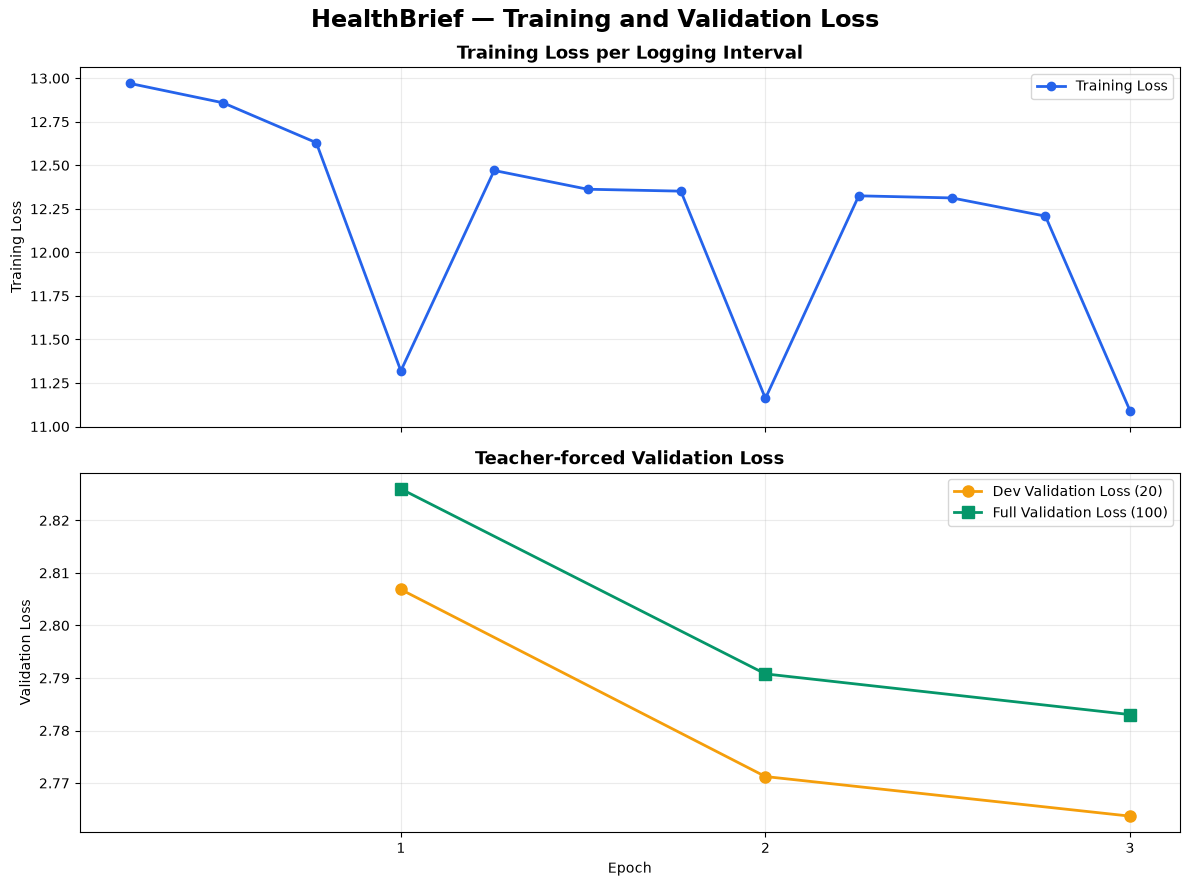

In [74]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True
)

axes[0].plot(
    train_logs["epoch"],
    train_logs["loss"],
    color="#2563EB",
    marker="o",
    linewidth=2,
    markersize=6,
    label="Training Loss"
)

axes[0].set_title(
    "Training Loss per Logging Interval",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Training Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    dev_logs["epoch"],
    dev_logs["eval_loss"],
    color="#F59E0B",
    marker="o",
    linewidth=2,
    markersize=8,
    label="Dev Validation Loss (20)"
)

axes[1].plot(
    full_validation_logs["epoch"],
    full_validation_logs["eval_full_loss"],
    color="#059669",
    marker="s",
    linewidth=2,
    markersize=8,
    label="Full Validation Loss (100)"
)

axes[1].set_title(
    "Teacher-forced Validation Loss",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].set_xticks([1, 2, 3])
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle(
    "HealthBrief — Training and Validation Loss",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

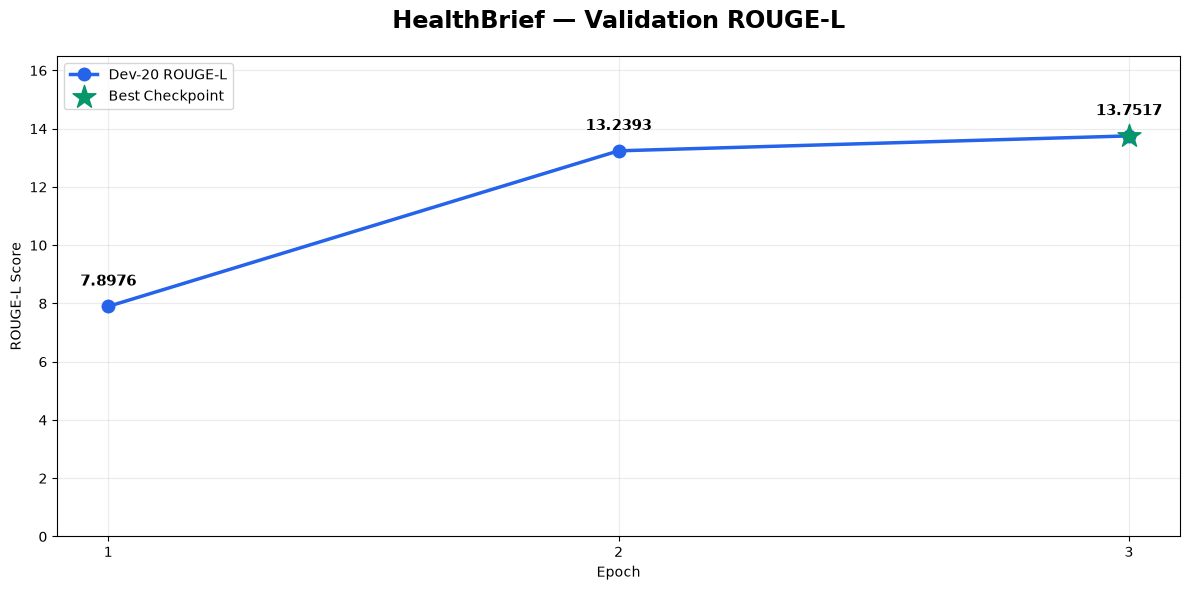

In [75]:
best_row = rouge_logs.loc[
    rouge_logs["eval_rougeL"].idxmax()
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    rouge_logs["epoch"],
    rouge_logs["eval_rougeL"],
    color="#2563EB",
    marker="o",
    markersize=9,
    linewidth=2.5,
    label="Dev-20 ROUGE-L"
)

ax.scatter(
    best_row["epoch"],
    best_row["eval_rougeL"],
    color="#059669",
    marker="*",
    s=300,
    zorder=5,
    label="Best Checkpoint"
)

for _, row in rouge_logs.iterrows():
    ax.annotate(
        f'{row["eval_rougeL"]:.4f}',
        (row["epoch"], row["eval_rougeL"]),
        textcoords="offset points",
        xytext=(0, 15),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "HealthBrief — Validation ROUGE-L",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Epoch")
ax.set_ylabel("ROUGE-L Score")
ax.set_xticks([1, 2, 3])
ax.set_ylim(0, rouge_logs["eval_rougeL"].max() * 1.20)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    figures_dir / "validation_rouge_l.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

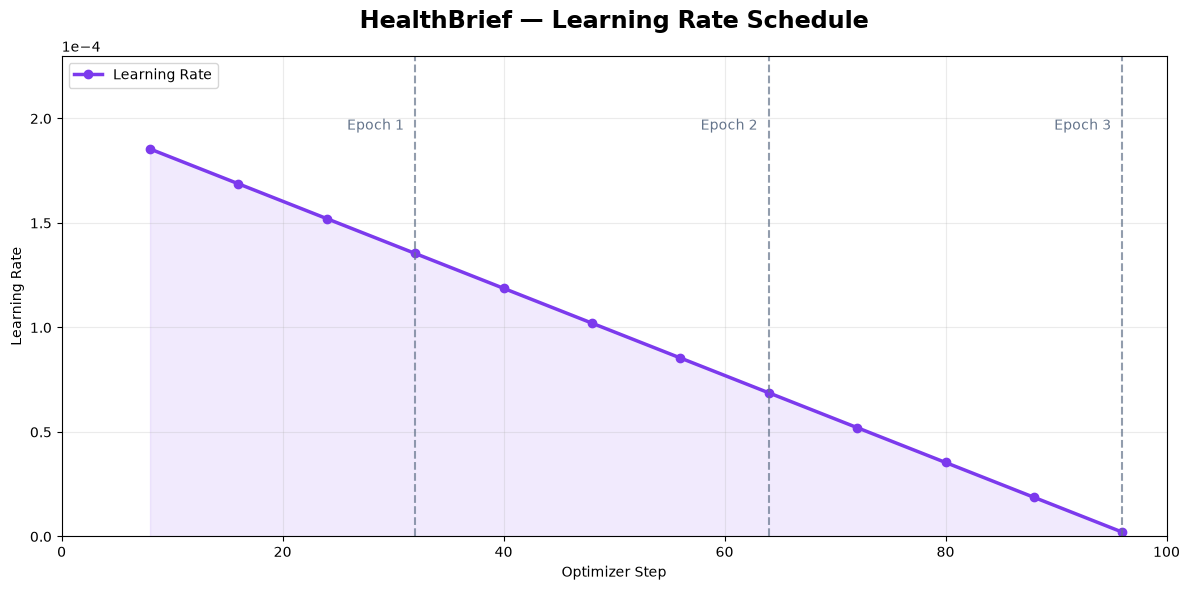

In [76]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    lr_logs["step"],
    lr_logs["learning_rate"],
    color="#7C3AED",
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="Learning Rate"
)

ax.fill_between(
    lr_logs["step"],
    lr_logs["learning_rate"],
    alpha=0.10,
    color="#7C3AED"
)

for _, row in rouge_logs.iterrows():
    ax.axvline(
        x=row["step"],
        color="#64748B",
        linestyle="--",
        alpha=0.7
    )

    ax.annotate(
        f'Epoch {int(row["epoch"])}',
        xy=(row["step"], LEARNING_RATE),
        xytext=(-8, -8),
        textcoords="offset points",
        ha="right",
        color="#64748B",
        fontsize=10
    )

ax.set_title(
    "HealthBrief — Learning Rate Schedule",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Optimizer Step")
ax.set_ylabel("Learning Rate")

ax.ticklabel_format(
    axis="y",
    style="scientific",
    scilimits=(0, 0)
)

ax.set_xlim(0, actual_optimizer_steps + 4)
ax.set_ylim(0, LEARNING_RATE * 1.15)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    figures_dir / "learning_rate_schedule.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
from pathlib import Path

checkpoint_dir = Path(training_args.output_dir)

checkpoints = sorted(
    checkpoint_dir.glob("checkpoint-*"),
    key=lambda path: int(path.name.split("-")[-1])
)

for checkpoint in checkpoints:
    print(checkpoint.name)


checkpoint_analysis = rouge_logs[[
    "epoch",
    "step",
    "eval_rougeL"
]].copy()

checkpoint_analysis["checkpoint"] = (
    "checkpoint-" +
    checkpoint_analysis["step"].astype(int).astype(str)
)

checkpoint_analysis = checkpoint_analysis.rename(
    columns={
        "eval_rougeL": "dev_rougeL"
    }
)

checkpoint_analysis["is_best"] = (
    checkpoint_analysis["checkpoint"]
    == Path(trainer.state.best_model_checkpoint).name
)

display(checkpoint_analysis)

checkpoint-32
checkpoint-64
checkpoint-96


,epoch,step,dev_rougeL,checkpoint,is_best
5,1.0,32,7.897638,checkpoint-32,False
11,2.0,64,13.239314,checkpoint-64,False
17,3.0,96,13.751730,checkpoint-96,True


In [79]:
best_checkpoint_row = checkpoint_analysis.loc[
    checkpoint_analysis["dev_rougeL"].idxmax()
]

best_epoch = best_checkpoint_row["epoch"]

best_rougeL = best_checkpoint_row["dev_rougeL"]

selected_checkpoint = best_checkpoint_row["checkpoint"]

print("Best Epoch:", best_epoch)
print("Best Dev ROUGE-L:", best_rougeL)
print("Selected Checkpoint:", selected_checkpoint)

assert selected_checkpoint == Path(
    trainer.state.best_model_checkpoint
).name

Best Epoch: 3.0
Best Dev ROUGE-L: 13.751729578646366
Selected Checkpoint: checkpoint-96


In [80]:
from peft import get_peft_model_state_dict
from safetensors.torch import load_file

best_checkpoint_path = Path(
    trainer.state.best_model_checkpoint
)

checkpoint_weights = load_file(
    str(best_checkpoint_path / "adapter_model.safetensors"),
    device="cpu"
)

current_adapter_weights = get_peft_model_state_dict(
    trainer.model
)

assert set(checkpoint_weights) == set(current_adapter_weights)

weight_comparison = []

for name, saved_weight in checkpoint_weights.items():

    current_weight = current_adapter_weights[name].detach().cpu()

    is_equal = torch.equal(
        saved_weight,
        current_weight
    )

    weight_comparison.append({
        "parameter_name": name,
        "parameter_count": saved_weight.numel(),
        "weights_equal": is_equal
    })

weight_comparison_df = pd.DataFrame(weight_comparison)

display(weight_comparison_df)

print("Total Adapter Tensors:", len(weight_comparison_df))

print(
    "Matching Tensors:",
    weight_comparison_df["weights_equal"].sum()
)

assert weight_comparison_df["weights_equal"].all()

print("Best Checkpoint Weight Verification: PASS")

,parameter_name,parameter_count,weights_equal
0,base_model.model.decoder.block.0.layer.0.SelfA...,4096,True
1,base_model.model.decoder.block.0.layer.0.SelfA...,3072,True
2,base_model.model.decoder.block.0.layer.0.SelfA...,4096,True
3,base_model.model.decoder.block.0.layer.0.SelfA...,3072,True
4,base_model.model.decoder.block.0.layer.1.EncDe...,4096,True
...,...,...,...
91,base_model.model.encoder.block.6.layer.0.SelfA...,3072,True
92,base_model.model.encoder.block.7.layer.0.SelfA...,4096,True
93,base_model.model.encoder.block.7.layer.0.SelfA...,3072,True
94,base_model.model.encoder.block.7.layer.0.SelfA...,4096,True


Total Adapter Tensors: 96
Matching Tensors: 96
Best Checkpoint Weight Verification: PASS


In [81]:
from peft import get_peft_model_state_dict
from safetensors.torch import load_file

best_checkpoint_path = Path(
    trainer.state.best_model_checkpoint
)

checkpoint_weights = load_file(
    str(best_checkpoint_path / "adapter_model.safetensors"),
    device="cpu"
)

current_adapter_weights = get_peft_model_state_dict(
    trainer.model
)

assert set(checkpoint_weights) == set(current_adapter_weights)

print("Saved Adapter Tensors:", len(checkpoint_weights))
print("Current Adapter Tensors:", len(current_adapter_weights))



Saved Adapter Tensors: 96
Current Adapter Tensors: 96


In [82]:
weight_comparison = []

for name, saved_weight in checkpoint_weights.items():

    current_weight = current_adapter_weights[name].detach().cpu()

    is_equal = torch.equal(
        saved_weight,
        current_weight
    )

    weight_comparison.append({
        "parameter_name": name,
        "parameter_count": saved_weight.numel(),
        "weights_equal": is_equal
    })

weight_comparison_df = pd.DataFrame(weight_comparison)

display(weight_comparison_df)

print("Total Adapter Tensors:", len(weight_comparison_df))

print(
    "Matching Tensors:",
    weight_comparison_df["weights_equal"].sum()
)

assert weight_comparison_df["weights_equal"].all()

print("Best Checkpoint Weight Verification: PASS")

,parameter_name,parameter_count,weights_equal
0,base_model.model.decoder.block.0.layer.0.SelfA...,4096,True
1,base_model.model.decoder.block.0.layer.0.SelfA...,3072,True
2,base_model.model.decoder.block.0.layer.0.SelfA...,4096,True
3,base_model.model.decoder.block.0.layer.0.SelfA...,3072,True
4,base_model.model.decoder.block.0.layer.1.EncDe...,4096,True
...,...,...,...
91,base_model.model.encoder.block.6.layer.0.SelfA...,3072,True
92,base_model.model.encoder.block.7.layer.0.SelfA...,4096,True
93,base_model.model.encoder.block.7.layer.0.SelfA...,3072,True
94,base_model.model.encoder.block.7.layer.0.SelfA...,4096,True


Total Adapter Tensors: 96
Matching Tensors: 96
Best Checkpoint Weight Verification: PASS


In [83]:
best_adapter_dir = project_dir / "models" / "healthbrief_best_adapter"

best_adapter_dir.mkdir(parents=True, exist_ok=True)

trainer.model.save_pretrained(
    best_adapter_dir
)

tokenizer.save_pretrained(
    best_adapter_dir
)

print("Best adapter saved:", best_adapter_dir)

Best adapter saved: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/models/healthbrief_best_adapter


In [84]:
adapter_files = []

for file in best_adapter_dir.rglob("*"):

    if file.is_file():

        size_bytes = file.stat().st_size

        adapter_files.append({
            "file_name": file.name,
            "size_bytes": size_bytes,
            "size_kib": size_bytes / 1024,
            "size_mib": size_bytes / 1024 ** 2
        })

adapter_files_df = pd.DataFrame(adapter_files)

display(adapter_files_df)

,file_name,size_bytes,size_kib,size_mib
0,adapter_config.json,1115,1.088867,0.001063
1,README.md,5164,5.042969,0.004925
2,tokenizer.json,2424069,2367.254883,2.311772
3,tokenizer_config.json,2381,2.325195,0.002271
4,adapter_model.safetensors,1389456,1356.890625,1.325089


In [85]:
saved_adapter_weights = load_file(
    str(best_adapter_dir / "adapter_model.safetensors"),
    device="cpu"
)

saved_adapter_details = []

for name, tensor in saved_adapter_weights.items():

    saved_adapter_details.append({
        "parameter_name": name,
        "shape": tuple(tensor.shape),
        "dtype": str(tensor.dtype),
        "parameter_count": tensor.numel(),
        "is_lora": "lora_A" in name or "lora_B" in name
    })

saved_adapter_details_df = pd.DataFrame(
    saved_adapter_details
)

display(saved_adapter_details_df)

,parameter_name,shape,dtype,parameter_count,is_lora
0,base_model.model.decoder.block.0.layer.0.SelfA...,"(8, 512)",torch.float32,4096,True
1,base_model.model.decoder.block.0.layer.0.SelfA...,"(384, 8)",torch.float32,3072,True
2,base_model.model.decoder.block.0.layer.0.SelfA...,"(8, 512)",torch.float32,4096,True
3,base_model.model.decoder.block.0.layer.0.SelfA...,"(384, 8)",torch.float32,3072,True
4,base_model.model.decoder.block.0.layer.1.EncDe...,"(8, 512)",torch.float32,4096,True
...,...,...,...,...,...
91,base_model.model.encoder.block.6.layer.0.SelfA...,"(384, 8)",torch.float32,3072,True
92,base_model.model.encoder.block.7.layer.0.SelfA...,"(8, 512)",torch.float32,4096,True
93,base_model.model.encoder.block.7.layer.0.SelfA...,"(384, 8)",torch.float32,3072,True
94,base_model.model.encoder.block.7.layer.0.SelfA...,"(8, 512)",torch.float32,4096,True


In [86]:
saved_tensor_count = len(saved_adapter_details_df)

saved_parameter_count = saved_adapter_details_df[
    "parameter_count"
].sum()

saved_lora_tensor_count = saved_adapter_details_df[
    "is_lora"
].sum()

saved_base_tensor_count = (
    saved_tensor_count - saved_lora_tensor_count
)

print("Saved Tensor Count:", saved_tensor_count)
print("Saved Parameter Count:", saved_parameter_count)
print("Saved LoRA Tensor Count:", saved_lora_tensor_count)
print("Saved Base Tensor Count:", saved_base_tensor_count)

assert saved_tensor_count == 96
assert saved_parameter_count == 344064
assert saved_base_tensor_count == 0

print("Adapter Content Verification: PASS")

Saved Tensor Count: 96
Saved Parameter Count: 344064
Saved LoRA Tensor Count: 96
Saved Base Tensor Count: 0
Adapter Content Verification: PASS


In [87]:
original_generate = trainer.args.predict_with_generate
original_loss_only = trainer.args.prediction_loss_only
original_compute_metrics = trainer.compute_metrics

try:
    trainer.args.predict_with_generate = False
    trainer.args.prediction_loss_only = True
    trainer.compute_metrics = None

    full_validation_metrics = Seq2SeqTrainer.evaluate(
        trainer,
        eval_dataset=loss_validation_dataset,
        metric_key_prefix="full_validation"
    )

finally:
    trainer.args.predict_with_generate = original_generate
    trainer.args.prediction_loss_only = original_loss_only
    trainer.compute_metrics = original_compute_metrics

print(full_validation_metrics)

Training Loss,Validation Loss,Epoch
11.091480,2.783029,3


{'full_validation_loss': 2.7830286026000977}


In [88]:
full_validation_loss = full_validation_metrics[
    "full_validation_loss"
]

best_model_summary = pd.DataFrame([{
    "best_epoch": best_epoch,
    "best_checkpoint": selected_checkpoint,
    "best_dev_20_rougeL": best_rougeL,
    "full_validation_100_loss": full_validation_loss
}])

display(best_model_summary)

,best_epoch,best_checkpoint,best_dev_20_rougeL,full_validation_100_loss
0,3.0,checkpoint-96,13.75173,2.783029


In [89]:
from contextlib import nullcontext
from types import SimpleNamespace
from torch.nn.utils.rnn import pad_sequence
import time

eval_model = trainer.model

eval_model.eval()

device = next(eval_model.parameters()).device

evaluation_batches = [
    data_collator([
        rouge_validation_dataset[j]
        for j in range(
            i,
            min(i + EVAL_BATCH_SIZE, len(rouge_validation_dataset))
        )
    ])
    for i in range(
        0,
        len(rouge_validation_dataset),
        EVAL_BATCH_SIZE
    )
]

print("Evaluation Samples:", len(rouge_validation_dataset))
print("Evaluation Batches:", len(evaluation_batches))
print("Device:", device)

Evaluation Samples: 20
Evaluation Batches: 5
Device: cuda:0


In [90]:
def evaluate_generations(eval_model, disable_lora=False):

    eval_model.eval()

    prediction_rows = []
    label_rows = []

    adapter_context = (
        eval_model.disable_adapter()
        if disable_lora
        else nullcontext()
    )

    with adapter_context, torch.inference_mode():

        torch.cuda.synchronize()

        start_time = time.perf_counter()

        for batch in evaluation_batches:

            inputs = {
                key: batch[key].to(device)
                for key in ["input_ids", "attention_mask"]
            }

            with torch.autocast("cuda", dtype=torch.bfloat16):

                generated = eval_model.generate(
                    **inputs,
                    max_length=GENERATION_MAX_LENGTH,
                    num_beams=GENERATION_NUM_BEAMS,
                    do_sample=DO_SAMPLE
                )

            prediction_rows.extend(
                generated.cpu().unbind(0)
            )

            label_rows.extend(
                batch["labels"].cpu().unbind(0)
            )

        torch.cuda.synchronize()

        inference_time = time.perf_counter() - start_time

    predictions = pad_sequence(
        prediction_rows,
        batch_first=True,
        padding_value=tokenizer.pad_token_id
    ).numpy()

    labels = pad_sequence(
        label_rows,
        batch_first=True,
        padding_value=-100
    ).numpy()

    eval_pred = SimpleNamespace(
        predictions=predictions,
        label_ids=labels
    )

    metrics = compute_rouge_metrics(eval_pred)

    decoded_predictions = tokenizer.batch_decode(
        predictions,
        skip_special_tokens=True
    )

    decoded_labels = tokenizer.batch_decode(
        np.where(
            labels == -100,
            tokenizer.pad_token_id,
            labels
        ),
        skip_special_tokens=True
    )

    special_token_ids = set(tokenizer.all_special_ids)

    generated_lengths = [
        sum(
            token_id not in special_token_ids
            for token_id in row.tolist()
        )
        for row in prediction_rows
    ]

    metrics["mean_generated_tokens"] = np.mean(
        generated_lengths
    )

    metrics["inference_time_seconds"] = inference_time

    return {
        "metrics": metrics,
        "predictions": decoded_predictions,
        "references": decoded_labels,
        "generated_lengths": generated_lengths
    }

In [92]:
zero_shot_results = evaluate_generations(
    eval_model,
    disable_lora=True
)

lora_results = evaluate_generations(
    eval_model,
    disable_lora=False
)

print("Zero-Shot Results:")
print(zero_shot_results["metrics"])

print("\nLoRA Results:")
print(lora_results["metrics"])

Zero-Shot Results:
{'rouge1': np.float64(5.163355013812019), 'rouge2': np.float64(1.379273872971888), 'rougeL': np.float64(4.2625398202713365), 'invalid_generation_count': 0, 'mean_generated_tokens': np.float64(61.55), 'inference_time_seconds': 5.05005410800004}

LoRA Results:
{'rouge1': np.float64(14.19723998445649), 'rouge2': np.float64(1.478052144061124), 'rougeL': np.float64(13.274526093657549), 'invalid_generation_count': 0, 'mean_generated_tokens': np.float64(752.4), 'inference_time_seconds': 25.78577086000041}


In [94]:
metric_mapping = {
    "ROUGE-1": "rouge1",
    "ROUGE-2": "rouge2",
    "ROUGE-L": "rougeL",
    "Mean Generated Tokens": "mean_generated_tokens",
    "Empty Outputs": "invalid_generation_count",
    "Inference Time (seconds)": "inference_time_seconds"
}

comparison_records = []

for metric_name, metric_key in metric_mapping.items():

    zero_shot_value = zero_shot_results["metrics"][metric_key]

    lora_value = lora_results["metrics"][metric_key]

    comparison_records.append({
        "metric": metric_name,
        "zero_shot": zero_shot_value,
        "lora_fine_tuned": lora_value,
        "difference": lora_value - zero_shot_value
    })

lora_baseline_comparison = pd.DataFrame(
    comparison_records
)

display(lora_baseline_comparison)

lora_baseline_comparison.to_csv(
    reports_dir / "lora_baseline_comparison.csv",
    index=False
)

,metric,zero_shot,lora_fine_tuned,difference
0,ROUGE-1,5.163355,14.197240,9.033885
1,ROUGE-2,1.379274,1.478052,0.098778
2,ROUGE-L,4.262540,13.274526,9.011986
3,Mean Generated Tokens,61.550000,752.400000,690.850000
4,Empty Outputs,0.000000,0.000000,0.000000
5,Inference Time (seconds),5.050054,25.785771,20.735717


In [95]:
qualitative_indices = [0, 4, 9, 14, 19]

print([
    rouge_validation_indices[i]
    for i in qualitative_indices
])

[7, 36, 61, 75, 94]


In [96]:
qualitative_records = []

for index in qualitative_indices:

    validation_index = rouge_validation_indices[index]

    prepared_sample = prepared_dataset["validation"][
        validation_index
    ]

    tokenized_sample = rouge_validation_dataset[index]

    qualitative_records.append({
        "validation_index": validation_index,
        "article_id": prepared_sample["article_id"],
        "source_text": tokenizer.decode(
            tokenized_sample["input_ids"],
            skip_special_tokens=True
        ),
        "reference_summary": lora_results["references"][index],
        "zero_shot_summary": zero_shot_results["predictions"][index],
        "lora_summary": lora_results["predictions"][index],
        "zero_shot_tokens": zero_shot_results[
            "generated_lengths"
        ][index],
        "lora_tokens": lora_results[
            "generated_lengths"
        ][index]
    })

qualitative_df = pd.DataFrame(
    qualitative_records
)

display(qualitative_df)

,validation_index,article_id,source_text,reference_summary,zero_shot_summary,lora_summary,zero_shot_tokens,lora_tokens
0,7,7efeca2a488b9111ef27539b80dcff4b76d1475d14ecc7...,Summarize the following biomedical research ar...,Genetic material is contained within molecules...,"flc-2 ) , the fusion proteins are functional a...",The fusion proteins are a fusion of a molecule...,18,767
1,36,d53bc7090137e9ef8d847c7326474bf93ef64f030a5619...,Summarize the following biomedical research ar...,"Our bodies—especially our skin , our saliva , ...",Molecular forensic analysis of microbial commu...,We demonstrated that microbial community chang...,23,767
2,61,937faa8e4054aea35c3c71be3629c785247dcb4b013768...,Summarize the following biomedical research ar...,"Neurons , the cells that make up the nervous s...",Fluorescence and action potentials are a commo...,Fluorescence and action potentials are a key f...,17,767
3,75,64565fd70435c136e972f02afa2da6fc858b58cc8df340...,Summarize the following biomedical research ar...,The genome of an individual organism contains ...,Molecular chromosomes are characterized by a r...,A chromosome-evolution of a haploid inducer is...,767,767
4,94,4fc672f1ba84812f5b6dc9aab7552ba8167b4ba1f0f48b...,Summarize the following biomedical research ar...,Understanding how genes are activated and sile...,"chromatin markers are found in human cells, we...",chromatin markers are a key component of the s...,26,767


In [97]:
for _, sample in qualitative_df.iterrows():

    print("=" * 100)
    print("VALIDATION INDEX:", sample["validation_index"])
    print("ARTICLE ID:", sample["article_id"])

    print("\nSOURCE TEXT:\n")
    print(sample["source_text"])

    print("\nREFERENCE SUMMARY:\n")
    print(sample["reference_summary"])

    print("\nZERO-SHOT SUMMARY:\n")
    print(sample["zero_shot_summary"])

    print("\nLORA SUMMARY:\n")
    print(sample["lora_summary"])

    print("\nZERO-SHOT TOKENS:", sample["zero_shot_tokens"])
    print("LORA TOKENS:", sample["lora_tokens"])

    print("=" * 100)

VALIDATION INDEX: 7
ARTICLE ID: 7efeca2a488b9111ef27539b80dcff4b76d1475d14ecc7eacb522b13ab06e6fb

SOURCE TEXT:

Summarize the following biomedical research article in plain language for a general audience: Inheritance of gene expression states is fundamental for cells to ‘remember’ past events , such as environmental or developmental cues . The conserved Polycomb Repressive Complex 2 ( PRC2 ) maintains epigenetic repression of many genes in animals and plants and modifies chromatin at its targets . Histones modified by PRC2 can be inherited through cell division . However , it remains unclear whether this inheritance can direct long-term memory of individual gene expression states ( cis memory ) or instead if local chromatin states are dictated by the concentrations of diffusible factors ( trans memory ) . By monitoring the expression of two copies of the Arabidopsis Polycomb target gene FLOWERING LOCUS C ( FLC ) in the same plants , we show that one copy can be repressed while the oth

In [98]:
error_columns = [
    "unsupported_claim",
    "contradiction",
    "important_omission",
    "terminology_error",
    "uncertainty_error",
    "incomplete_summary",
    "severe_repetition"
]

manual_annotations = {
    7: {
        "zero_shot": [
            "no", "no", "yes", "no",
            "no", "yes", "no"
        ],
        "lora": [
            "unclear", "unclear", "yes", "yes",
            "unclear", "yes", "yes"
        ]
    },
    36: {
        "zero_shot": [
            "yes", "yes", "yes", "no",
            "no", "yes", "no"
        ],
        "lora": [
            "no", "no", "yes", "no",
            "no", "yes", "yes"
        ]
    },
    61: {
        "zero_shot": [
            "no", "no", "yes", "no",
            "no", "yes", "no"
        ],
        "lora": [
            "yes", "no", "yes", "no",
            "no", "yes", "yes"
        ]
    },
    75: {
        "zero_shot": [
            "unclear", "unclear", "yes", "yes",
            "unclear", "yes", "yes"
        ],
        "lora": [
            "unclear", "unclear", "yes", "yes",
            "unclear", "yes", "yes"
        ]
    },
    94: {
        "zero_shot": [
            "no", "no", "yes", "no",
            "no", "yes", "no"
        ],
        "lora": [
            "yes", "no", "yes", "yes",
            "no", "yes", "yes"
        ]
    }
}

In [99]:
analysis_notes = {
    7: {
        "zero_shot": (
            "Correctly mentions functional fusion proteins but "
            "omits cis epigenetic memory and inheritance of FLC expression."
        ),
        "lora": (
            "Severe phrase repetition involving molecules. "
            "Fails to communicate the main epigenetic finding."
        )
    },
    36: {
        "zero_shot": (
            "Misrepresents the experimental organisms as humans and swine "
            "instead of mice. Omits the 48-day study and 3-day estimation accuracy."
        ),
        "lora": (
            "Identifies the relationship between microbial changes and PMI "
            "but repeatedly generates the same sentence and omits key findings."
        )
    },
    61: {
        "zero_shot": (
            "Mentions fluorescence and action potentials but omits "
            "the limitations of action potential detection."
        ),
        "lora": (
            "Introduces an unsupported claim about the development "
            "of neural dynamics and repeatedly generates the same sentence."
        )
    },
    75: {
        "zero_shot": (
            "Severe repetition and unclear chromosome terminology. "
            "Omits chromosome shattering, DNA Ligase 4 and heritability."
        ),
        "lora": (
            "Severe repetition of phenotype terminology. "
            "Does not communicate the main genome elimination findings."
        )
    },
    94: {
        "zero_shot": (
            "Captures the general purpose of identifying MAE genes "
            "but omits the specific chromatin marks and reported frequencies."
        ),
        "lora": (
            "Confuses monoallelic gene expression with autosomal gene synthesis. "
            "Produces severe sentence repetition."
        )
    }
}

In [100]:
qualitative_analysis_records = []

for _, sample in qualitative_df.iterrows():

    validation_index = int(sample["validation_index"])

    for model_name in ["zero_shot", "lora"]:

        annotations = dict(zip(
            error_columns,
            manual_annotations[validation_index][model_name]
        ))

        qualitative_analysis_records.append({
            "validation_index": validation_index,
            "article_id": sample["article_id"],
            "model": model_name,
            "source_text": sample["source_text"],
            "reference_summary": sample["reference_summary"],
            "generated_summary": sample[f"{model_name}_summary"],
            "generated_tokens": sample[f"{model_name}_tokens"],
            **annotations,
            "analysis_notes": analysis_notes[
                validation_index
            ][model_name]
        })

qualitative_summary_comparison = pd.DataFrame(
    qualitative_analysis_records
)

display(qualitative_summary_comparison)

,validation_index,article_id,model,source_text,reference_summary,generated_summary,generated_tokens,unsupported_claim,contradiction,important_omission,terminology_error,uncertainty_error,incomplete_summary,severe_repetition,analysis_notes
0,7,7efeca2a488b9111ef27539b80dcff4b76d1475d14ecc7...,zero_shot,Summarize the following biomedical research ar...,Genetic material is contained within molecules...,"flc-2 ) , the fusion proteins are functional a...",18,no,no,yes,no,no,yes,no,Correctly mentions functional fusion proteins ...
1,7,7efeca2a488b9111ef27539b80dcff4b76d1475d14ecc7...,lora,Summarize the following biomedical research ar...,Genetic material is contained within molecules...,The fusion proteins are a fusion of a molecule...,767,unclear,unclear,yes,yes,unclear,yes,yes,Severe phrase repetition involving molecules. ...
2,36,d53bc7090137e9ef8d847c7326474bf93ef64f030a5619...,zero_shot,Summarize the following biomedical research ar...,"Our bodies—especially our skin , our saliva , ...",Molecular forensic analysis of microbial commu...,23,yes,yes,yes,no,no,yes,no,Misrepresents the experimental organisms as hu...
3,36,d53bc7090137e9ef8d847c7326474bf93ef64f030a5619...,lora,Summarize the following biomedical research ar...,"Our bodies—especially our skin , our saliva , ...",We demonstrated that microbial community chang...,767,no,no,yes,no,no,yes,yes,Identifies the relationship between microbial ...
4,61,937faa8e4054aea35c3c71be3629c785247dcb4b013768...,zero_shot,Summarize the following biomedical research ar...,"Neurons , the cells that make up the nervous s...",Fluorescence and action potentials are a commo...,17,no,no,yes,no,no,yes,no,Mentions fluorescence and action potentials bu...
5,61,937faa8e4054aea35c3c71be3629c785247dcb4b013768...,lora,Summarize the following biomedical research ar...,"Neurons , the cells that make up the nervous s...",Fluorescence and action potentials are a key f...,767,yes,no,yes,no,no,yes,yes,Introduces an unsupported claim about the deve...
6,75,64565fd70435c136e972f02afa2da6fc858b58cc8df340...,zero_shot,Summarize the following biomedical research ar...,The genome of an individual organism contains ...,Molecular chromosomes are characterized by a r...,767,unclear,unclear,yes,yes,unclear,yes,yes,Severe repetition and unclear chromosome termi...
7,75,64565fd70435c136e972f02afa2da6fc858b58cc8df340...,lora,Summarize the following biomedical research ar...,The genome of an individual organism contains ...,A chromosome-evolution of a haploid inducer is...,767,unclear,unclear,yes,yes,unclear,yes,yes,Severe repetition of phenotype terminology. Do...
8,94,4fc672f1ba84812f5b6dc9aab7552ba8167b4ba1f0f48b...,zero_shot,Summarize the following biomedical research ar...,Understanding how genes are activated and sile...,"chromatin markers are found in human cells, we...",26,no,no,yes,no,no,yes,no,Captures the general purpose of identifying MA...
9,94,4fc672f1ba84812f5b6dc9aab7552ba8167b4ba1f0f48b...,lora,Summarize the following biomedical research ar...,Understanding how genes are activated and sile...,chromatin markers are a key component of the s...,767,yes,no,yes,yes,no,yes,yes,Confuses monoallelic gene expression with auto...


In [101]:
qualitative_summary_comparison.to_csv(
    reports_dir / "qualitative_summary_comparison.csv",
    index=False
)